# 01 · EDA del texto de las quejas

**Objetivo:** conocer el corpus antes de etiquetar: cuánto texto hay, de qué se quejan los clientes y qué clases de la taxonomía van a ser escasas.

**Datos:** reseñas de 1–2 estrellas de Amazon Reviews Multi (español), ya limpias por `src/data/prepare.py`.

> Este notebook solo muestra agregados. Los textos de las reseñas no se reproducen.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data.prepare import build_complaints
from src.labeling.gold import POSTVENTA_PATTERN

AZUL, NARANJA = "#2a78d6", "#eb6834"  # 1 estrella, 2 estrellas
TINTA, SECUNDARIA, TENUE, REJILLA = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLOR_ESTRELLAS = {1: AZUL, 2: NARANJA}
NOMBRE_ESTRELLAS = {1: "1 estrella", 2: "2 estrellas"}

plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "grid.color": REJILLA,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "text.color": TINTA,
        "axes.labelcolor": SECUNDARIA,
        "xtick.color": TENUE,
        "ytick.color": TENUE,
        "xtick.labelcolor": SECUNDARIA,
        "ytick.labelcolor": SECUNDARIA,
        "ytick.left": False,
        "xtick.bottom": False,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "font.size": 10,
        "legend.frameon": False,
    }
)

df = pd.read_parquet(ROOT / "data/processed/quejas.parquet")
print(f"{len(df):,} quejas · columnas: {list(df.columns)}")

79,753 quejas · columnas: ['review_id', 'estrellas', 'titulo', 'cuerpo', 'texto', 'n_tokens', 'texto_tfidf']


## 1. Del dataset crudo al corpus de quejas

In [2]:
_, funnel = build_complaints(pd.read_parquet(ROOT / "data/raw/train.parquet"))
embudo = pd.DataFrame({"filas": funnel})
embudo["descartadas"] = -embudo["filas"].diff().fillna(0).astype(int)
embudo

,filas,descartadas
reseñas,200000,0
1-2 estrellas,80000,120000
con 5+ palabras,79809,191
sin duplicados,79753,56


In [3]:
df["estrellas"].value_counts().sort_index().rename("quejas").to_frame()

,quejas
estrellas,
1,39867
2,39886


## 2. Longitud de las quejas

In [4]:
percentiles = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
df.groupby("estrellas")["n_tokens"].describe(percentiles=percentiles).round(1)

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
estrellas,,,,,,,,,,,
1,39867.0,31.9,23.9,5.0,8.0,17.0,26.0,39.0,76.0,123.0,417.0
2,39886.0,34.9,26.2,5.0,9.0,19.0,28.0,43.0,84.0,134.0,511.0


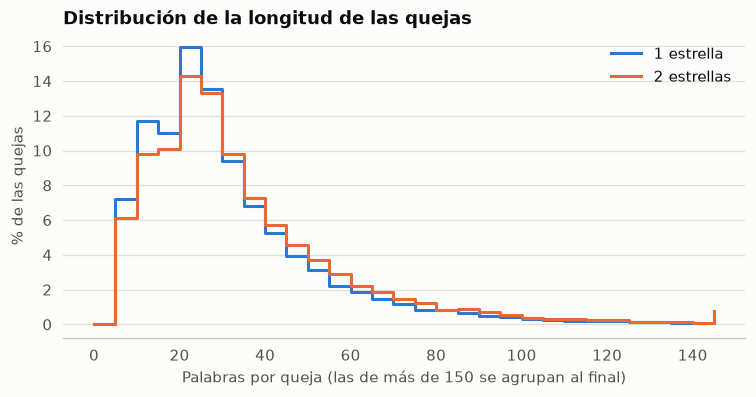

Menos de 10 palabras: 6.7%
Menos de 40 palabras: 73.2%
Más de 100 palabras:  2.4%


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 155, 5)
for estrellas, grupo in df.groupby("estrellas"):
    cuenta, _ = np.histogram(grupo["n_tokens"].clip(upper=150), bins=bins)
    ax.step(
        bins[:-1],
        cuenta / len(grupo) * 100,
        where="post",
        lw=2,
        color=COLOR_ESTRELLAS[estrellas],
        label=NOMBRE_ESTRELLAS[estrellas],
    )
ax.set(
    title="Distribución de la longitud de las quejas",
    xlabel="Palabras por queja (las de más de 150 se agrupan al final)",
    ylabel="% de las quejas",
)
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

print(f"Menos de 10 palabras: {(df['n_tokens'] < 10).mean():.1%}")
print(f"Menos de 40 palabras: {(df['n_tokens'] < 40).mean():.1%}")
print(f"Más de 100 palabras:  {(df['n_tokens'] > 100).mean():.1%}")

## 3. Palabras y pares de palabras más frecuentes

Se calculan sobre `texto_tfidf` (lemas, sin palabras funcionales, sin tildes). La medida es el **% de quejas que contienen el término**, no el número de apariciones.

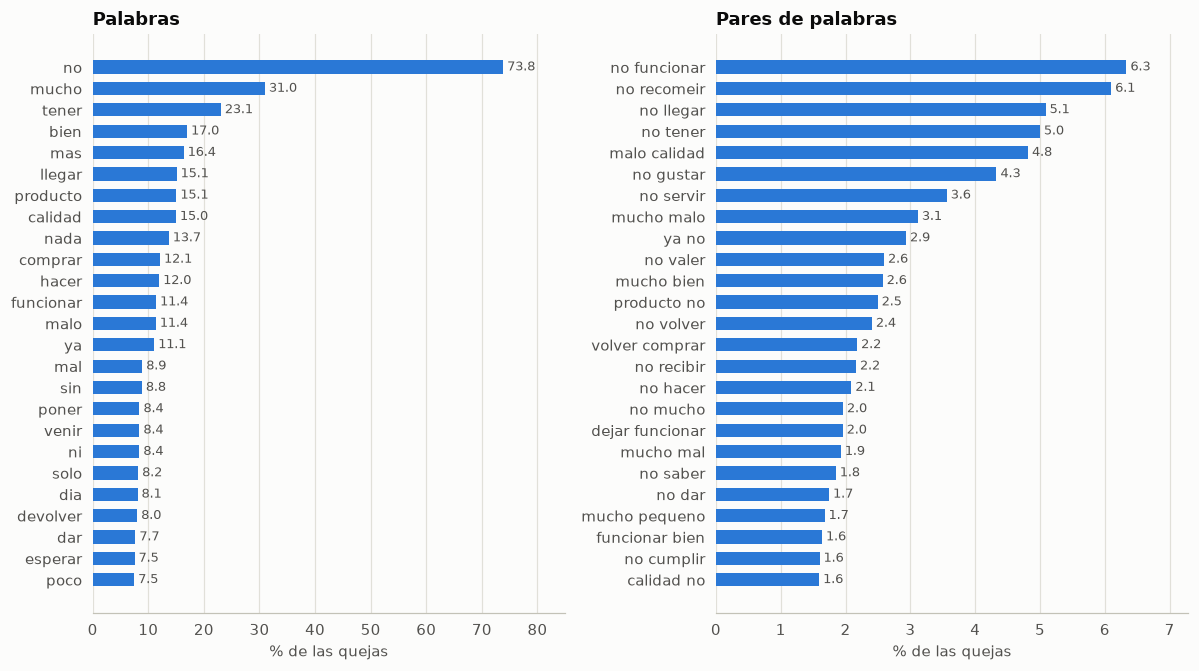

Vocabulario con 50+ quejas: 2,233 palabras, 2,078 pares


In [6]:
def frecuencia_documental(textos, ngram_range, min_df=50):
    vec = CountVectorizer(ngram_range=ngram_range, min_df=min_df, binary=True)
    matriz = vec.fit_transform(textos)
    share = np.asarray(matriz.mean(axis=0)).ravel() * 100
    return pd.Series(share, index=vec.get_feature_names_out()).sort_values(ascending=False)


def barras(serie, titulo, ax, color=AZUL):
    serie = serie.iloc[::-1]
    ax.barh(serie.index, serie.values, color=color, height=0.62)
    for y, valor in enumerate(serie.values):
        ax.text(valor, y, f" {valor:.1f}", va="center", fontsize=8.5, color=SECUNDARIA)
    ax.set(title=titulo, xlabel="% de las quejas")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, serie.max() * 1.15)


unigramas = frecuencia_documental(df["texto_tfidf"], (1, 1))
bigramas = frecuencia_documental(df["texto_tfidf"], (2, 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 6.2))
barras(unigramas.head(25), "Palabras", axes[0])
barras(bigramas.head(25), "Pares de palabras", axes[1])
fig.tight_layout()
plt.show()
print(f"Vocabulario con 50+ quejas: {len(unigramas):,} palabras, {len(bigramas):,} pares")

## 4. ¿En qué se diferencian 1 y 2 estrellas?

Razón de probabilidades (log-odds con suavizado) de cada término entre los dos grupos. Sirve para anticipar si las estrellas ayudan a separar temas o urgencia.

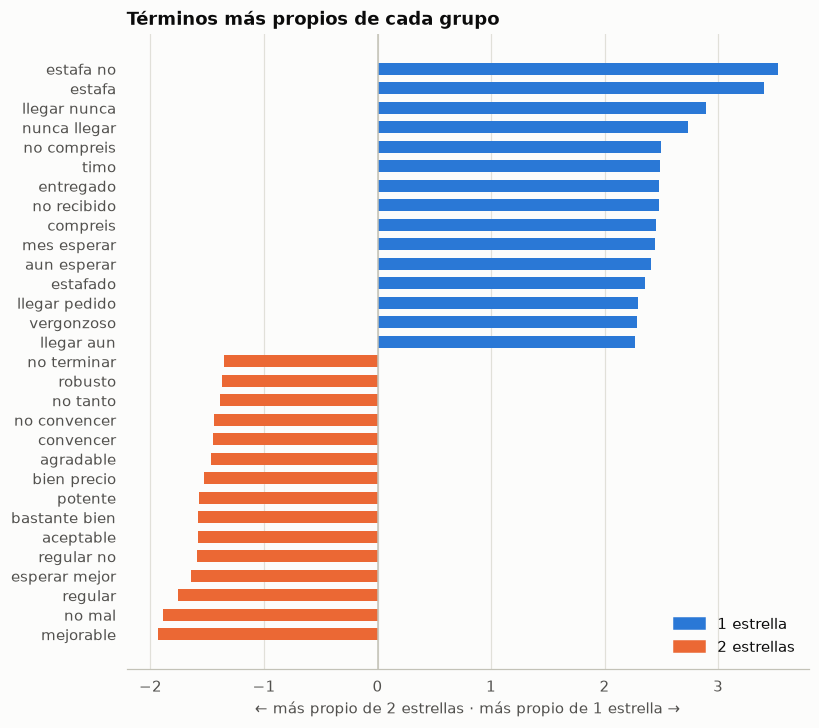

,log_odds,% en 1 estrella,% en 2 estrellas
estafa no,3.53,0.42,0.01
estafa,3.41,2.00,0.07
llegar nunca,2.90,0.58,0.03
nunca llegar,2.73,2.18,0.14
no compreis,2.49,0.81,0.07
timo,2.49,1.58,0.13
entregado,2.48,0.80,0.07
no recibido,2.48,0.50,0.04
compreis,2.45,0.83,0.07
mes esperar,2.44,0.51,0.04


In [7]:
vec = CountVectorizer(ngram_range=(1, 2), min_df=150, binary=True)
X = vec.fit_transform(df["texto_tfidf"])
es_1 = (df["estrellas"] == 1).to_numpy()
n1, n2 = es_1.sum(), (~es_1).sum()
c1 = np.asarray(X[es_1].sum(axis=0)).ravel()
c2 = np.asarray(X[~es_1].sum(axis=0)).ravel()
log_odds = np.log((c1 + 1) / (n1 - c1 + 1)) - np.log((c2 + 1) / (n2 - c2 + 1))
contraste = pd.DataFrame(
    {"log_odds": log_odds, "% en 1 estrella": c1 / n1 * 100, "% en 2 estrellas": c2 / n2 * 100},
    index=vec.get_feature_names_out(),
)

extremos = pd.concat(
    [contraste.nlargest(15, "log_odds"), contraste.nsmallest(15, "log_odds")]
).sort_values("log_odds")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(
    extremos.index,
    extremos["log_odds"],
    height=0.62,
    color=[AZUL if v > 0 else NARANJA for v in extremos["log_odds"]],
)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set(
    title="Términos más propios de cada grupo",
    xlabel="← más propio de 2 estrellas · más propio de 1 estrella →",
)
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)],
    labels=["1 estrella", "2 estrellas"],
    loc="lower right",
)
plt.show()
extremos.round(2).iloc[::-1]

## 5. Señales de cada tema de la taxonomía

Antes de etiquetar no hay temas reales, así que se usa una aproximación: expresiones regulares que detectan si una queja **menciona** cada tema. Una mención no es el motivo principal (una queja puede mencionar varios o ninguno), así que estos porcentajes son orientativos, no la distribución de clases.

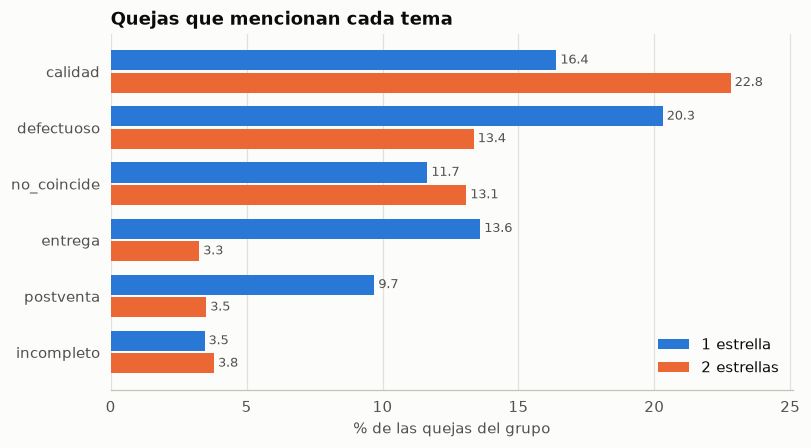

estrellas,1,2,total
calidad,16.4,22.8,19.6
defectuoso,20.3,13.4,16.8
no_coincide,11.7,13.1,12.4
entrega,13.6,3.3,8.4
postventa,9.7,3.5,6.6
incompleto,3.5,3.8,3.6


In [8]:
SENALES = {
    "entrega": (
        r"no (?:me |nos )?(?:ha |han )?lleg|no (?:lo |la |los |las )?he recibido|nunca (?:me )?lleg"
        r"|sin recibir|retras|repartidor|mensajer|llegó tarde|tard[oó] "
    ),
    "defectuoso": (
        r"rot[oa]s?\b|no funciona|dej[oó] de funcionar|defectuos|averiad|estrope|se rompi"
        r"|se (?:ha |me ha )?roto|no enciende|no carga|dañad|se ha partido"
    ),
    "no_coincide": (
        r"no (?:es|era) (?:lo|el|la) que|no corresponde|no coincide|nada que ver|diferente a"
        r"|distint[oa]|falsific|imitaci[oó]n|talla|no es original|no es compatible"
        r"|en la foto|descripci[oó]n"
    ),
    "incompleto": (
        r"\bfaltan?\b|\bfaltaba|incomplet|sin instrucciones|no trae|no incluye"
        r"|solo (?:llega|llegó|viene|vino|trae|recib)"
    ),
    "calidad": (
        r"calidad|endeble|fr[aá]gil|cutre|de pl[aá]stico|poco resistente|muy fin[oa]"
        r"|no merece la pena|car[oa] para"
    ),
    "postventa": POSTVENTA_PATTERN,
}
texto_min = df["texto"].str.lower()
senales = pd.DataFrame(
    {tema: texto_min.str.contains(patron, regex=True) for tema, patron in SENALES.items()}
)

por_estrellas = senales.groupby(df["estrellas"]).mean().T * 100
por_estrellas["total"] = senales.mean() * 100
por_estrellas = por_estrellas.sort_values("total")

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(por_estrellas))
for desplazamiento, estrellas in [(0.2, 1), (-0.2, 2)]:
    valores = por_estrellas[estrellas]
    ax.barh(
        y + desplazamiento,
        valores,
        height=0.36,
        color=COLOR_ESTRELLAS[estrellas],
        label=NOMBRE_ESTRELLAS[estrellas],
    )
    for yi, valor in zip(y + desplazamiento, valores, strict=True):
        ax.text(valor, yi, f" {valor:.1f}", va="center", fontsize=8.5, color=SECUNDARIA)
ax.set_yticks(y, por_estrellas.index)
ax.set(title="Quejas que mencionan cada tema", xlabel="% de las quejas del grupo")
ax.set_xlim(0, por_estrellas[[1, 2]].to_numpy().max() * 1.1)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()
por_estrellas.round(1).iloc[::-1]

In [9]:
etiquetas = {0: "ninguna", 1: "una", 2: "dos", 3: "tres o más"}
n_senales = senales.sum(axis=1).clip(upper=3).map(etiquetas)
solapamiento = (n_senales.value_counts(normalize=True) * 100).reindex(etiquetas.values())
solapamiento.round(1).rename("% de las quejas").to_frame()

,% de las quejas
ninguna,45.9
una,42.2
dos,10.7
tres o más,1.3


### Pares de palabras más frecuentes entre las quejas que mencionan cada tema

In [10]:
top_por_tema = {}
for tema in SENALES:
    subset = df.loc[senales[tema], "texto_tfidf"]
    top = frecuencia_documental(subset, (2, 2), min_df=20).head(12)
    top_por_tema[f"{tema} (n={len(subset):,})"] = top.index.tolist()
pd.DataFrame(top_por_tema)

,"entrega (n=6,718)","defectuoso (n=13,425)","no_coincide (n=9,863)","incompleto (n=2,892)","calidad (n=15,635)","postventa (n=5,268)"
0,no llegar,no funcionar,no esperar,no traer,malo calidad,no llegar
1,no recibir,dejar funcionar,no tener,faltar pieza,mucho malo,no funcionar
2,nunca llegar,no recomeir,no corresponder,no tener,no recomeir,no tener
3,aun no,ya no,no recomeir,hacer falta,calidad no,no recibir
4,producto no,malo calidad,nada ver,solo venir,buen calidad,ya no
5,llegar producto,funcionar bien,no cubrir,no venir,bajo calidad,producto no
6,llegar no,funcionar no,pantalla no,no llegar,no tener,vendedor no
7,todavia no,no tener,no gustar,venir sin,calidad precio,no recomeir
8,devolver dinero,mucho malo,no funcionar,sin instruccion,merecer pena,no responder
9,no tener,mucho bien,cubrir pantalla,no recomeir,no merecer,hacer devolucion


## 6. La muestra del gold set

`gold_sample.csv` tiene 400 quejas al azar (estratificadas por estrellas y longitud) y 100 dirigidas a candidatas de *postventa*. La parte aleatoria debe parecerse al corpus.

In [11]:
muestra = pd.read_csv(ROOT / "data/labeled/gold_sample.csv").merge(df, on="review_id")


def perfil(d):
    con_senal = d["texto"].str.contains(POSTVENTA_PATTERN, case=False, regex=True)
    return {
        "quejas": len(d),
        "% 1 estrella": (d["estrellas"] == 1).mean() * 100,
        "mediana de palabras": d["n_tokens"].median(),
        "% con señal de postventa": con_senal.mean() * 100,
    }


pd.DataFrame(
    {
        "corpus": perfil(df),
        "gold aleatorio": perfil(muestra[muestra["origen"] == "aleatorio"]),
        "gold dirigido": perfil(muestra[muestra["origen"] == "dirigido"]),
    }
).round(1)

,corpus,gold aleatorio,gold dirigido
quejas,79753.0,400.0,100.0
% 1 estrella,50.0,50.0,79.0
mediana de palabras,27.0,27.0,34.5
% con señal de postventa,6.6,5.2,100.0


## 7. Conclusiones

**Corpus**
- Quedan **79 753 quejas**, repartidas casi exactamente a la mitad entre 1 y 2 estrellas. Los filtros apenas descartan nada: 191 por tener menos de 5 palabras y 56 duplicadas.
- Son textos cortos: mediana de 27 palabras, el 73 % tiene menos de 40 y solo el 2,4 % pasa de 100. Clasificarlas con un LLM costará pocos tokens por queja, pero los modelos tienen poco contexto por texto.

**Vocabulario**
- «no» aparece en el 74 % de las quejas y casi todos los pares más frecuentes son negaciones («no funcionar», «no llegar», «no recibir»). Conservar las negaciones en `clean_heavy` era imprescindible.
- El lematizador de spaCy comete errores sistemáticos: «recomiendo» → «recomeir» y «muy» → «mucho». Al ser consistentes no dañan a TF-IDF, pero en la Fase 2 conviene comparar con n-gramas de caracteres sobre el texto sin lematizar.

**Estrellas**
- Las quejas de 1 estrella concentran el vocabulario de entrega y de fraude («estafa», «nunca llegar», «no recibido»); las de 2 estrellas, el de decepción moderada («regular», «mejorable», «aceptable»).
- Entrega se menciona 4 veces más en 1 estrella (13,6 % frente a 3,3 %) y postventa casi 3 veces más (9,7 % frente a 3,5 %). Las estrellas son una señal útil para la urgencia.

**Taxonomía**
- Por menciones, el orden es calidad (19,6 %), defectuoso (16,8 %), no coincide (12,4 %), entrega (8,4 %), postventa (6,6 %) e incompleto (3,6 %).
- El 46 % de las quejas no activa ninguna señal y el 12 % activa dos o más. Las reglas de palabras clave no bastan como clasificador, y hace falta la regla de prioridad de `taxonomy.yaml` para elegir un solo tema.
- **Postventa** casi siempre acompaña a otro motivo («no llegar», «no funcionar»), así que como motivo principal será rara. Por eso el gold incluye 100 quejas dirigidas a esa clase.
- **Incompleto** solo se menciona en el 3,6 %. Si tras etiquetar queda por debajo del 5 %, se fusiona con *no coincide*.

**Gold set**
- La parte aleatoria reproduce el corpus (50 % de 1 estrella, mediana de 27 palabras). La parte dirigida se inclina hacia 1 estrella (79 %), como era de esperar. La distribución real de clases se debe estimar solo con la parte aleatoria.